In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from functools import partial
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from cdrmip_extremes import (
    amoc, processing, utils, io_disk, stats
)
from cdrmip_extremes.utils import _map_leaves, reduce_member_tree
from cdrmip_extremes.configs import DATA_DIR, PROC_DIR, CDR_MODELS, SSP_MODELS, COLOUR_DICT, FIG_DIR
from cdrmip_extremes.plotting import plot_gsat_timeseries

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

## Load CDRMIP data

In [3]:
def load_mip(mip, models, skip=()):
    def load(var, drop_coords=None, **kw):
        tree = io_disk.load_tree(PROC_DIR, var, mip, model_order=models, **kw)
        return utils.reduce_member_tree(tree, drop_coords=drop_coords) if drop_coords else utils.reduce_member_tree(tree)

    loaders = {
        'gsat':               lambda: load('gsat'),
        'gsat_rolling':       lambda: load('gsat_rolling'),
        'crossing_years':     lambda: load('crossing_years', as_dataarray=True),
        'gwl_matching_years': lambda: load('gwl_matching_years', as_dataarray=True, drop_coords=['gwl']),
        'amoc':               lambda: load('amoc', category='anomaly'),
        'pi_amoc':            lambda: load('amoc'),
        'peak_warming':       lambda: io_disk.load_peak_warming(mip, PROC_DIR),
    }
    return {k: f() for k, f in loaders.items() if k not in skip}

data = {
    'CDRMIP':      load_mip('CDRMIP', CDR_MODELS),
    'ScenarioMIP': load_mip('ScenarioMIP', None, skip={'pi_amoc', 'crossing_years'}),
}

## Gather AMOC strength information

In [4]:
MARKERS = {'ramp_up': dict(marker='^', s=400),
           'ramp_down': dict(marker='v', s=400),
           'peak': dict(marker='o', s=200)}

SSP_LABELS = {'ramp_up': 'Pre-peak warming GWL',
              'ramp_down': 'Post-peak warming GWL',
              'peak': 'Peak warming'}
CDR_LABELS = {'ramp_up': '1.5°C crossing (ramp-up)',
              'ramp_down': '1.5°C crossing (ramp-down)',
              'peak': 'Peak warming'}

def branch_years(key, gwl=None):
    def fn(d, model, expt):
        cy = d[key][model][expt]
        cy = cy.sel(gwl=gwl) if gwl is not None else cy.squeeze('gwl', drop=True)
        return {b: cy.sel(branch=b) for b in ('ramp_up', 'ramp_down')}
    return fn
    
PANELS = [
    ('ScenarioMIP', 'ssp534-over', branch_years('gwl_matching_years'), SSP_LABELS, dict(min_end_year=2101)),
    ('ScenarioMIP', 'ssp126',      branch_years('gwl_matching_years'), SSP_LABELS, dict()),
    ('CDRMIP',      '1pctCO2-cdr', branch_years('crossing_years', gwl=1.5), CDR_LABELS,
     dict(xlim=(0, 340), xticks=[0, 140, 280, 340])),
]


EXPT_NAMES = {'ssp534-over': 'SSP5-3.4-OS', 'ssp126': 'SSP1-2.6'}


def amoc_points(d, series, model, expt, years_fn):
    try:
        years = {k: float(v) for k, v in years_fn(d, model, expt).items()}
    except KeyError:  # no matching-year data for this model/experiment
        years = {}
    peaks = d['peak_warming'].get(model, {}).get(expt)
    if peaks:
        years['peak'] = np.median([p['peak_year'] for p in peaks.values()])
    years = {k: y for k, y in years.items() if np.isfinite(y)}
    return {k: (y, float(series.sel(year=y, method='nearest'))) for k, y in years.items()}

In [5]:
def plot_amoc_panel(d, expt, years_fn, labels, ax, min_end_year=None,
                    vlines=(), xticks=None, **plot_kw):
    raw = {m: {expt: ds} for m, ds in amoc_for(d, expt, min_end_year).items()}
    rolled = _map_leaves(raw, lambda ds: stats._rolling_mean(ds, 21, 'year'))

    plot_gsat_timeseries(rolled, COLOUR_DICT, raw_tree=raw, raw_alpha=0.3,
                         varname='amoc', title=EXPT_NAMES.get(expt, expt), xlabel='Year',
                         ylabel='AMOC anomaly at 26.5°N (Sv)', legend_loc=None, vlines=vlines,xticks=xticks,
                         fig=ax.figure, ax=ax, **plot_kw)

    for m in raw:
        for k, (x, y) in amoc_points(d, rolled[m][expt]['amoc'], m, expt, years_fn).items():
            ax.scatter(x, y, color=COLOUR_DICT[m], linewidth=0.8, zorder=4, **MARKERS[k])

    ax.legend(handles=[Line2D([], [], ls='', marker=MARKERS[k]['marker'], markersize=10,
                              color='lightgrey', label=lab) for k, lab in labels.items()],
              loc='lower left', fontsize=16, frameon=False, bbox_to_anchor = (-0.01,0.0))

## Plot of AMOC strength pre vs post peak warming

In [6]:
def amoc_for(d, expt, min_end_year=None):
    """{model: AMOC Dataset} for models with this experiment (optionally run past min_end_year)."""
    return {m: t[expt] for m, t in d['amoc'].items()
            if expt in t and (min_end_year is None or t[expt].year.max() > min_end_year)}

In [7]:
EXPT_MARKERS = {'1pctCO2-cdr': 'o', 'ssp534-over': 's', 'ssp126': 'D'}

def recovery_points(d, expt, years_fn, min_end_year=None):
    """{model: (AMOC pre-peak, AMOC post-peak)} at matched GWL."""
    out = {}
    for m, ds in amoc_for(d, expt, min_end_year).items():
        series = stats._rolling_mean(ds, 21, 'year')['amoc']
        pts = amoc_points(d, series, m, expt, years_fn)
        if 'ramp_up' in pts and 'ramp_down' in pts:
            out[m] = (pts['ramp_up'][1], pts['ramp_down'][1])
    return out

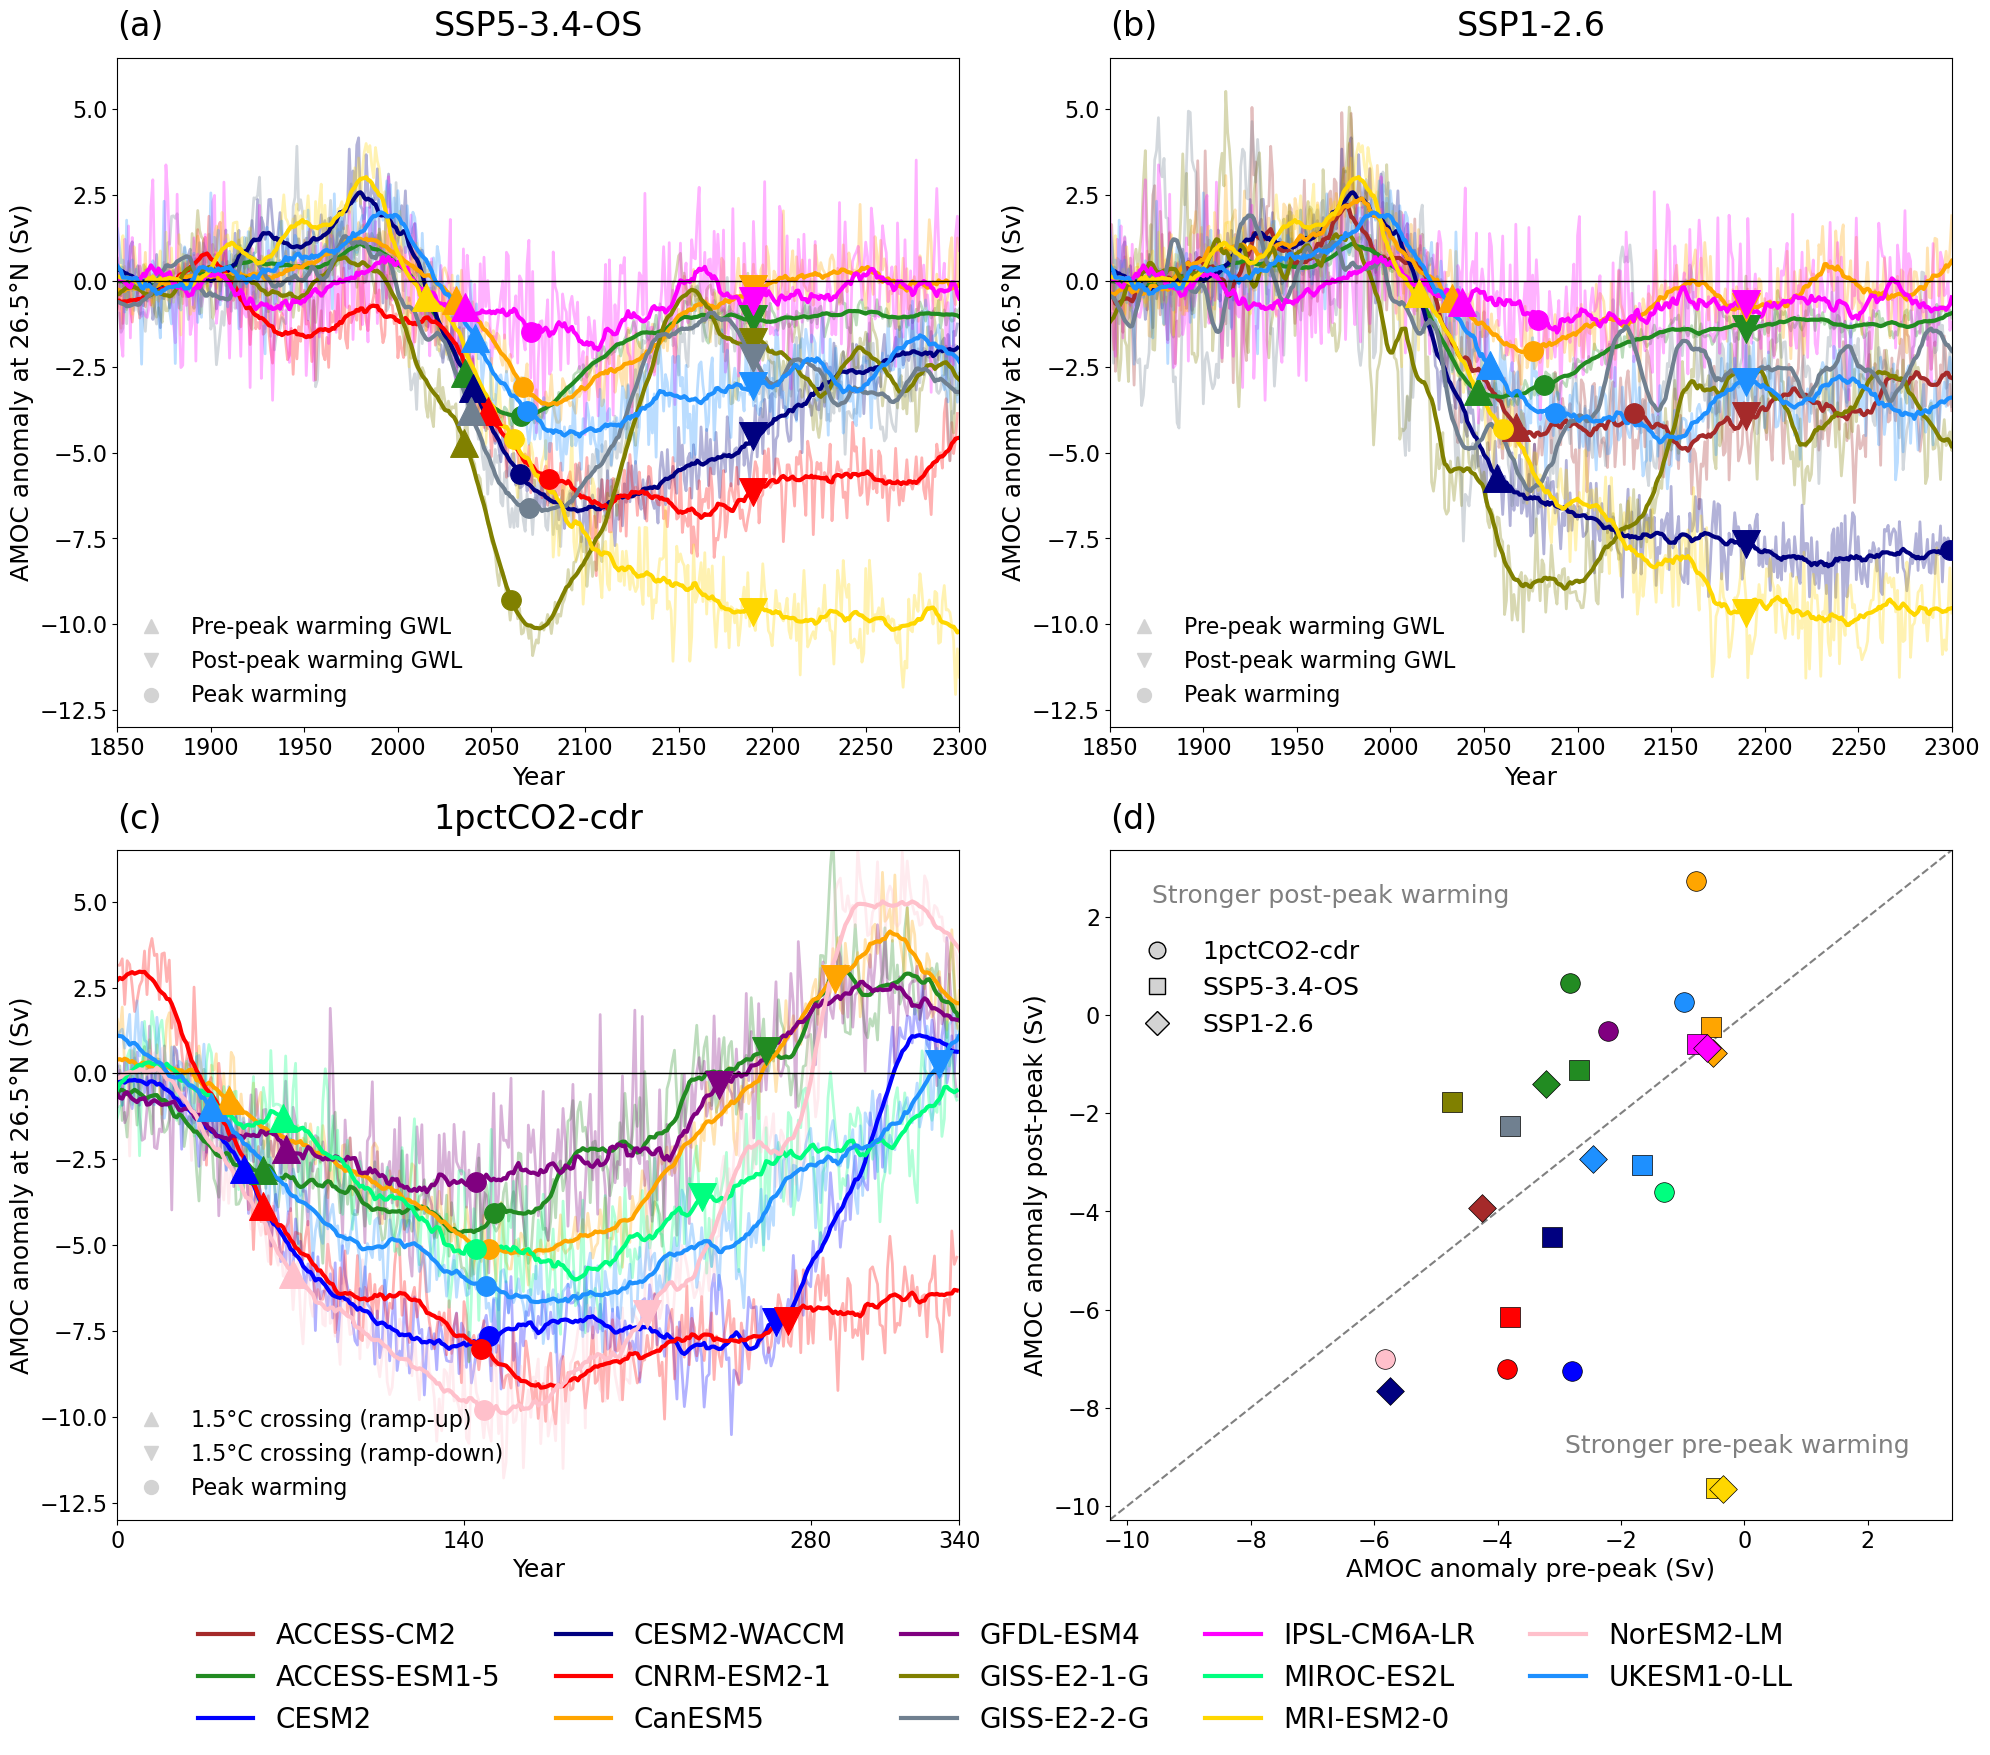

In [8]:
def plot_recovery(ax, panels):
    for mip, expt, years_fn, _, kw in panels:
        for m, (x, y) in recovery_points(data[mip], expt, years_fn, kw.get('min_end_year')).items():
            ax.scatter(x, y, color=COLOUR_DICT[m], marker=EXPT_MARKERS[expt],
                       s=200, edgecolor='k', linewidth=0.5, zorder=3)

    lo = min(ax.get_xlim()[0], ax.get_ylim()[0])
    hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.set(xlim=(lo, hi), ylim=(lo, hi))
    ax.set_xlabel('AMOC anomaly pre-peak (Sv)', fontsize=18)
    ax.set_ylabel('AMOC anomaly post-peak (Sv)', fontsize=18)
    ax.tick_params(axis="both", which="major", labelsize=16)
    # ax.tick_params(labelsize=14)
    ax.axline((0, 0), slope=1, color='grey', ls='--')
    ax.text(0.05, 0.95, 'Stronger post-peak warming', transform=ax.transAxes, va='top', fontsize=18, color='grey')
    ax.text(0.95, 0.10, 'Stronger pre-peak warming', transform=ax.transAxes, ha='right', fontsize=18, color='grey')
    ax.legend(handles=[Line2D([], [], ls='', marker=mk, markersize=12, color='lightgrey',
                              markeredgecolor='k', label=EXPT_NAMES.get(e, e)) for e, mk in EXPT_MARKERS.items()],
              loc='upper left', fontsize=18, bbox_to_anchor = (0.0, 0.9), frameon=False)

fig, axes = plt.subplots(2, 2, figsize=(20, 16))
*ts_axes, rec_ax = axes.flat

for ax, (mip, expt, years_fn, labels, kw) in zip(ts_axes, PANELS):
    plot_amoc_panel(data[mip], expt, years_fn, labels, ax, ylim=(-13, 6.5), **kw)
plot_recovery(rec_ax, PANELS)

model_handles = {}
for ax in ts_axes:
    model_handles.update(zip(*ax.get_legend_handles_labels()[::-1]))
    
model_handles = dict(sorted(model_handles.items()))
for ax, lab in zip(axes.flat, 'abcd'):
    ax.set_title(f'({lab})', loc='left', fontsize=24, y=1.02)
fig.tight_layout()
fig.legend(model_handles.values(), model_handles.keys(), loc='upper center',
           bbox_to_anchor=(0.5, 0), ncol=5, fontsize=20, frameon=False)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S31.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

## Other plots

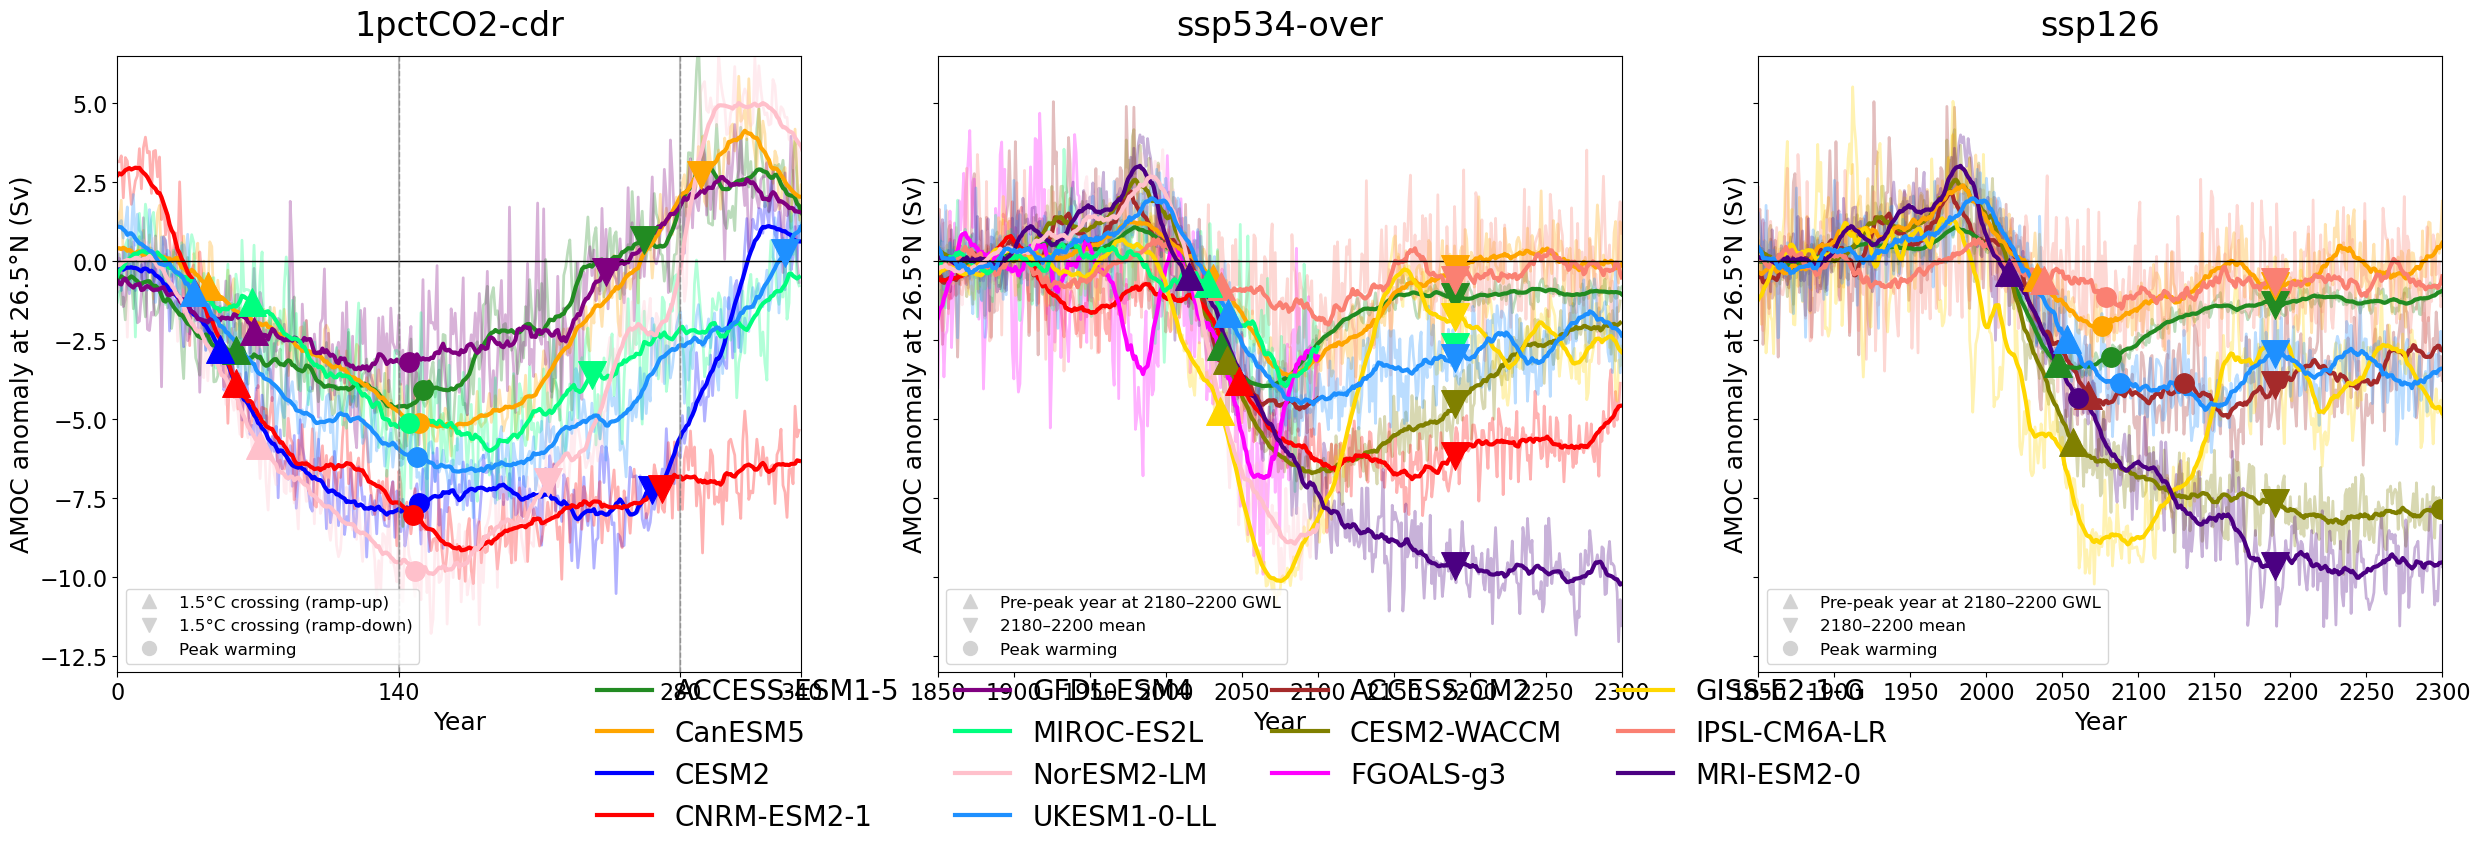

In [40]:


fig, axes = plt.subplots(1, len(PANELS), figsize=(30, 8), sharey=True)
for ax, (mip, expt, years_fn, labels, kw) in zip(axes, PANELS):
    plot_amoc_panel(data[mip], expt, years_fn, labels, ax, ylim=(-13, 6.5), **kw)

model_handles = {}
for ax in axes:
    model_handles.update(zip(*ax.get_legend_handles_labels()[::-1]))
fig.legend(model_handles.values(), model_handles.keys(), loc='lower center',
           ncol=4, fontsize=20, frameon=False, bbox_to_anchor=(0.5, -0.12))

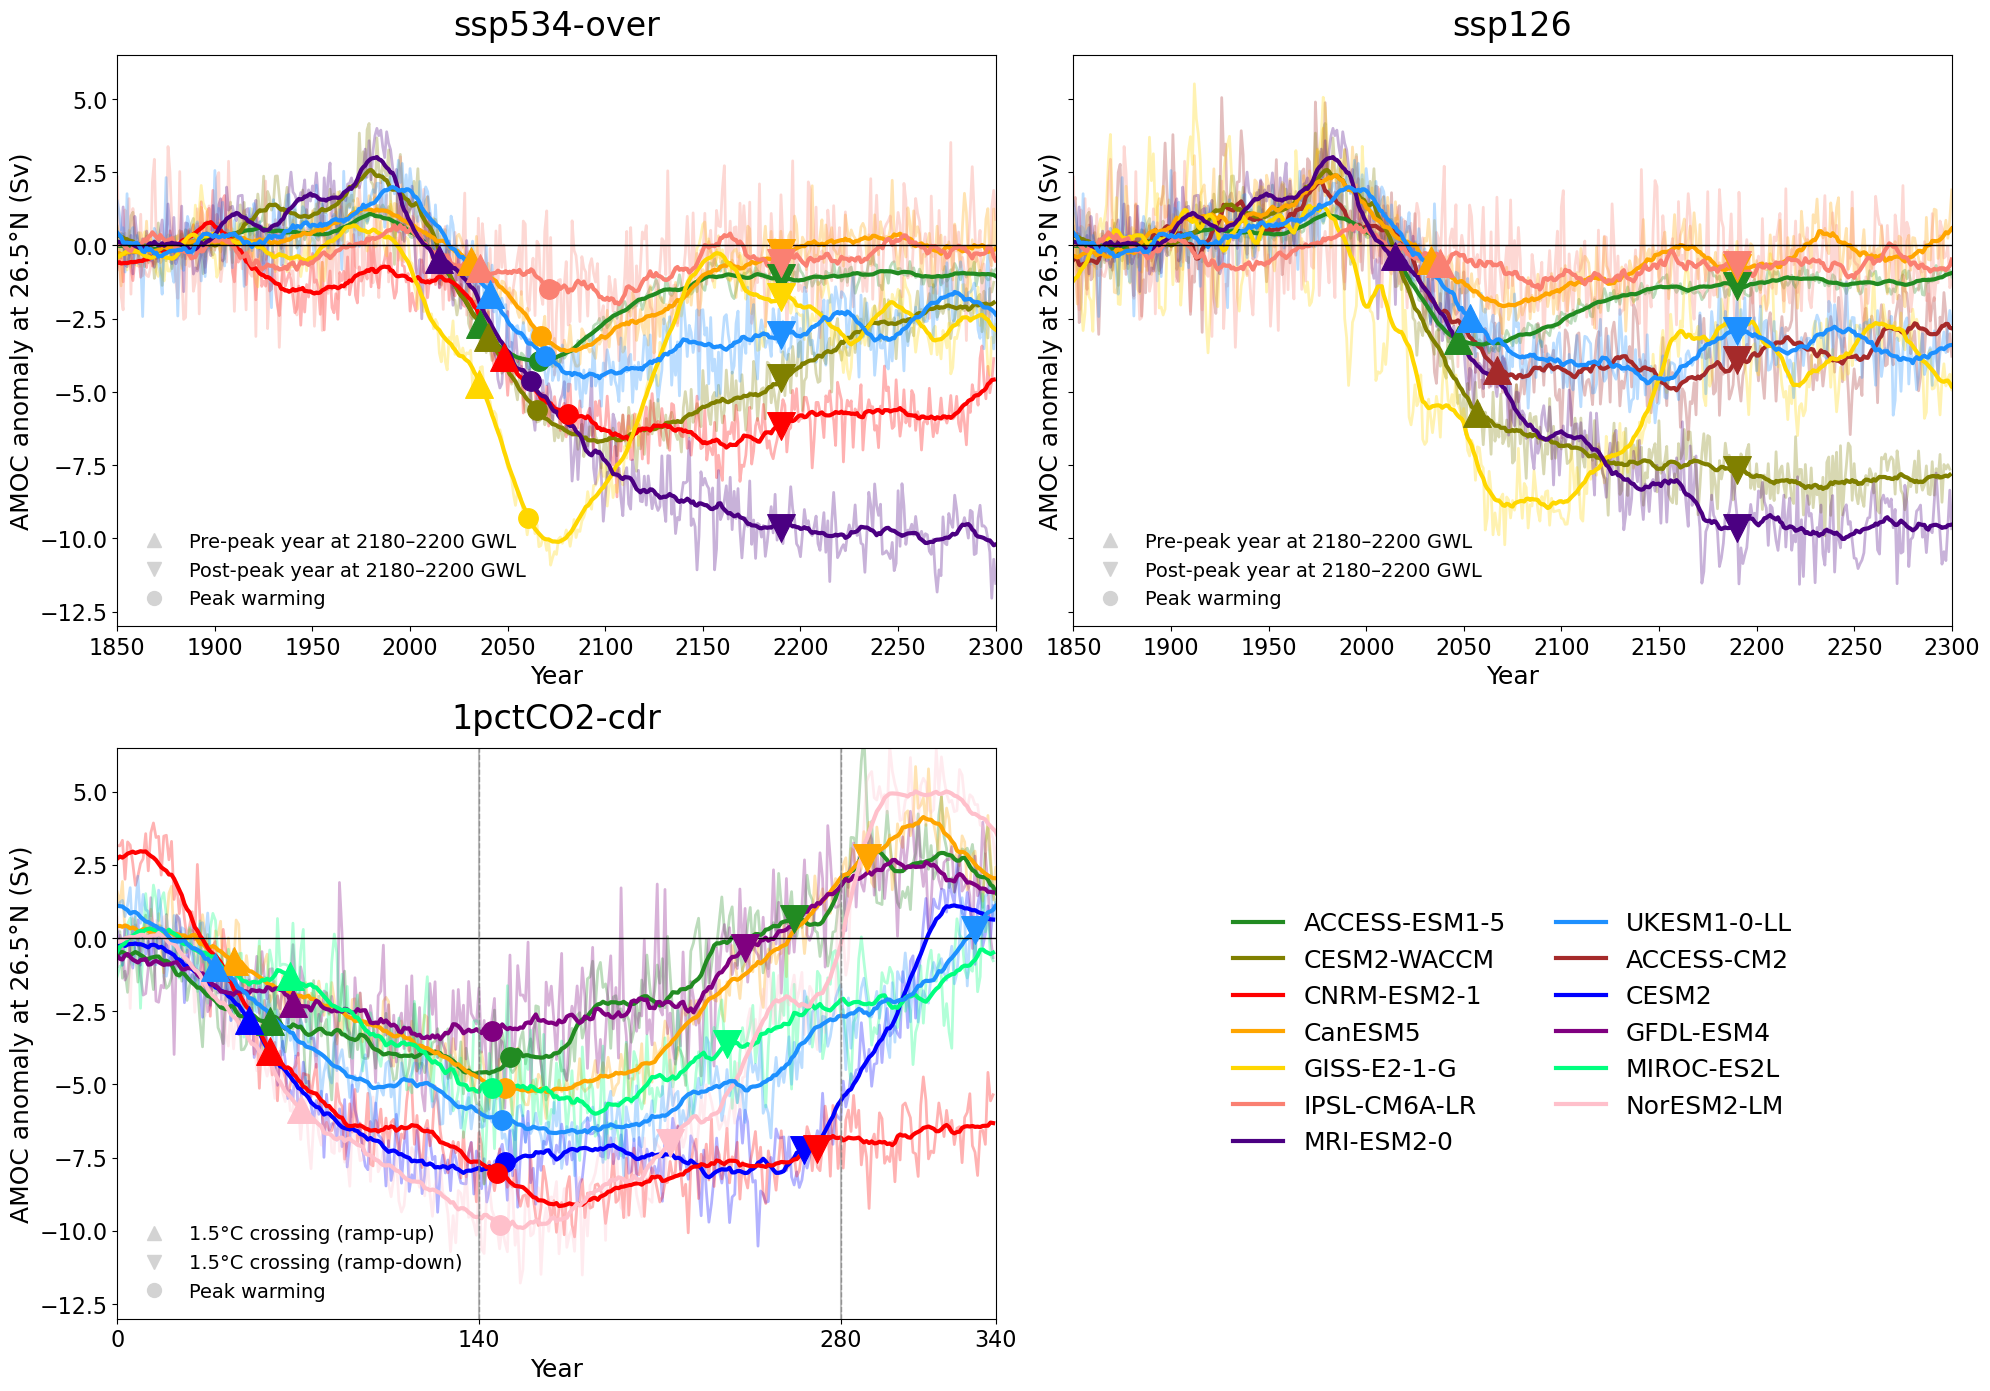

In [13]:


fig, axes = plt.subplots(2, 2, figsize=(20, 14), sharey=True)
*plot_axes, legend_ax = axes.flat

for ax, (mip, expt, years_fn, labels, kw) in zip(plot_axes, PANELS):
    plot_amoc_panel(data[mip], expt, years_fn, labels, ax, ylim=(-13, 6.5), **kw)

model_handles = {}
for ax in plot_axes:
    model_handles.update(zip(*ax.get_legend_handles_labels()[::-1]))

legend_ax.axis('off')
legend_ax.legend(model_handles.values(), model_handles.keys(), loc='center',
                 ncol=2, fontsize=18, frameon=False)
fig.tight_layout()